In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("seattleWeather_1948-2017.csv")
df.head()

,DATE,PRCP,TMAX,TMIN,RAIN
0,1948-01-01,0.47,51,42,True
1,1948-01-02,0.59,45,36,True
2,1948-01-03,0.42,45,35,True
3,1948-01-04,0.31,45,34,True
4,1948-01-05,0.17,45,32,True


In [3]:
# Create next day's rain column
df['NEXT_RAIN'] = df['RAIN'].shift(-1)

# Remove last row because it has no next day
df = df.dropna()

df.head()

,DATE,PRCP,TMAX,TMIN,RAIN,NEXT_RAIN
0,1948-01-01,0.47,51,42,True,True
1,1948-01-02,0.59,45,36,True,True
2,1948-01-03,0.42,45,35,True,True
3,1948-01-04,0.31,45,34,True,True
4,1948-01-05,0.17,45,32,True,True


In [4]:
transition_counts = pd.crosstab(df['RAIN'], df['NEXT_RAIN'])

print(transition_counts)

NEXT_RAIN  False  True 
RAIN                   
False      10957   3688
True        3689   7211


In [5]:
transition_matrix = transition_counts.div(transition_counts.sum(axis=1), axis=0)

print(transition_matrix)

NEXT_RAIN     False     True 
RAIN                         
False      0.748173  0.251827
True       0.338440  0.661560


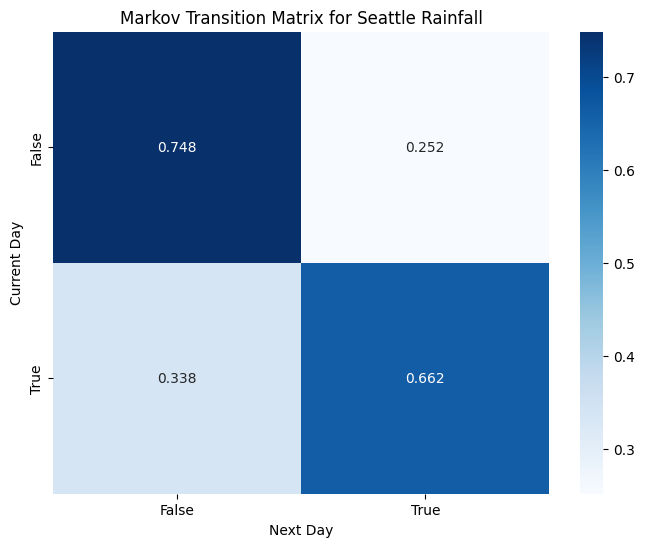

In [6]:
plt.figure(figsize=(8,6))

sns.heatmap(
    transition_matrix,
    annot=True,
    cmap="Blues",
    fmt=".3f"
)

plt.title("Markov Transition Matrix for Seattle Rainfall")
plt.xlabel("Next Day")
plt.ylabel("Current Day")

plt.show()

In [7]:
# stationary distribution hesaplama

eigenvalues, eigenvectors = np.linalg.eig(transition_matrix.T)

stationary = eigenvectors[:, np.isclose(eigenvalues, 1)]

stationary = stationary[:,0]

stationary = stationary / stationary.sum()

print(stationary)

[0.57336834 0.42663166]


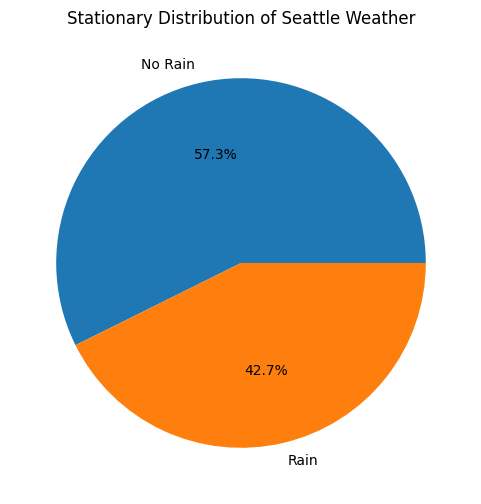

In [8]:
states = ["No Rain", "Rain"]

plt.figure(figsize=(6,6))

plt.pie(
    stationary,
    labels=states,
    autopct='%1.1f%%'
)

plt.title("Stationary Distribution of Seattle Weather")

plt.show()

In [9]:
# 3 günlük geçiş olasılıkları

three_step = np.linalg.matrix_power(transition_matrix.values, 3)

print(three_step)

[[0.60271482 0.39728518]
 [0.53392835 0.46607165]]


In [10]:
# sıcaklık durumları oluşturma

def temp_state(temp):
    
    if temp < 50:
        return "Cold"
    
    elif temp < 70:
        return "Mild"
    
    else:
        return "Hot"

df["TEMP_STATE"] = df["TMAX"].apply(temp_state)

df.head()

,DATE,PRCP,TMAX,TMIN,RAIN,NEXT_RAIN,TEMP_STATE
0,1948-01-01,0.47,51,42,True,True,Mild
1,1948-01-02,0.59,45,36,True,True,Cold
2,1948-01-03,0.42,45,35,True,True,Cold
3,1948-01-04,0.31,45,34,True,True,Cold
4,1948-01-05,0.17,45,32,True,True,Cold


In [11]:
# sonraki günün sıcaklık durumu

df["NEXT_TEMP_STATE"] = df["TEMP_STATE"].shift(-1)

df = df.dropna()

In [12]:
temp_transition_counts = pd.crosstab(
    df["TEMP_STATE"],
    df["NEXT_TEMP_STATE"]
)

print(temp_transition_counts)

NEXT_TEMP_STATE  Cold   Hot   Mild
TEMP_STATE                        
Cold             4702     0   1371
Hot                 0  4655   1392
Mild             1372  1392  10660


In [13]:
temp_transition_matrix = temp_transition_counts.div(
    temp_transition_counts.sum(axis=1),
    axis=0
)

print(temp_transition_matrix)

NEXT_TEMP_STATE      Cold       Hot      Mild
TEMP_STATE                                   
Cold             0.774247  0.000000  0.225753
Hot              0.000000  0.769803  0.230197
Mild             0.102205  0.103695  0.794100


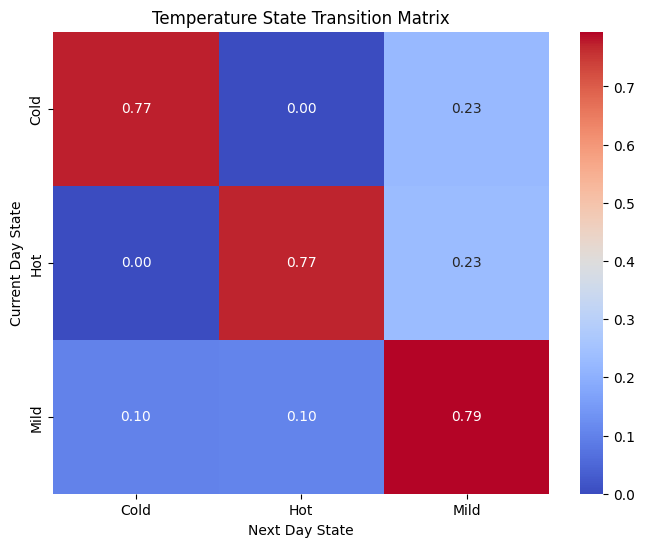

In [14]:
plt.figure(figsize=(8,6))

sns.heatmap(
    temp_transition_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Temperature State Transition Matrix")

plt.xlabel("Next Day State")
plt.ylabel("Current Day State")

plt.show()

In [15]:
import networkx as nx

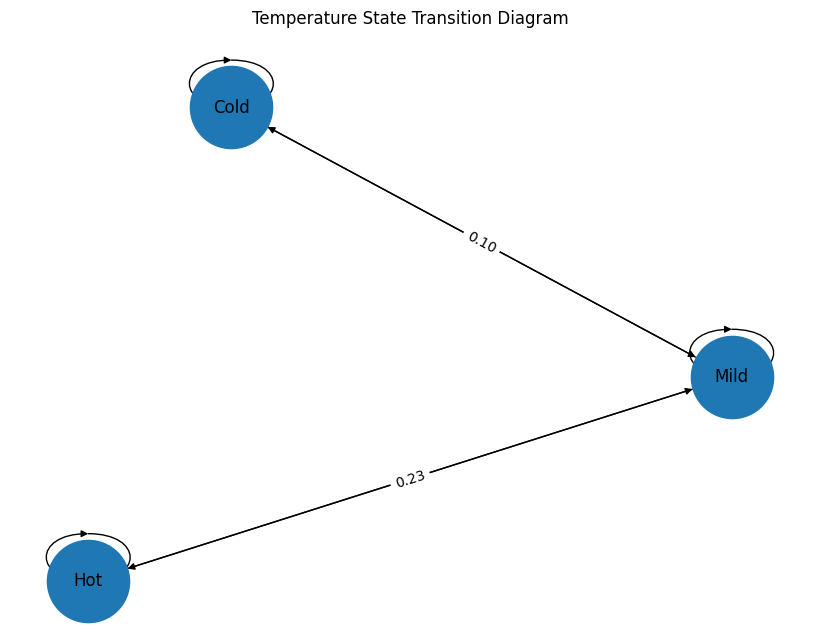

In [16]:
G = nx.DiGraph()

states = temp_transition_matrix.index

for state1 in states:
    for state2 in states:
        
        probability = temp_transition_matrix.loc[state1, state2]
        
        # sadece anlamlı geçişleri ekle
        if probability > 0.05:
            G.add_edge(state1, state2, weight=probability)

plt.figure(figsize=(8,6))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3500,
    font_size=12,
    arrows=True
)

edge_labels = {
    (u, v): f"{d['weight']:.2f}"
    for u, v, d in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels
)

plt.title("Temperature State Transition Diagram")

plt.show()


In [17]:
df["DATE"] = pd.to_datetime(df["DATE"])

df["YEAR"] = df["DATE"].dt.year

In [18]:
yearly_rain = df.groupby("YEAR")["RAIN"].mean()

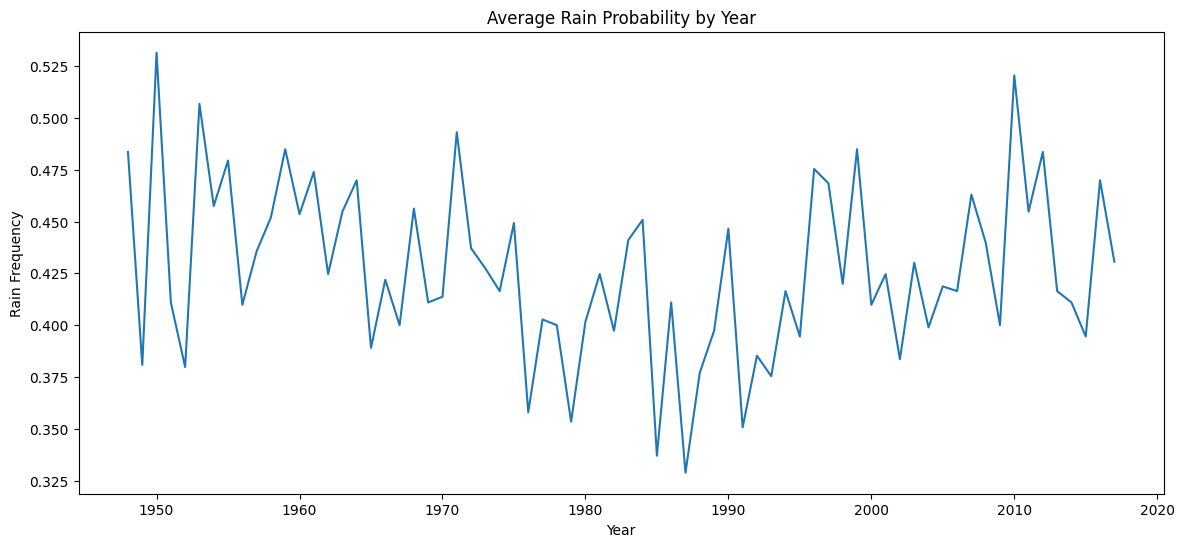

In [19]:
plt.figure(figsize=(14,6))

plt.plot(yearly_rain.index, yearly_rain.values)

plt.title("Average Rain Probability by Year")

plt.xlabel("Year")
plt.ylabel("Rain Frequency")

plt.show()

In [20]:
correlation = df[["PRCP", "TMAX", "TMIN"]].corr()

print(correlation)

          PRCP      TMAX      TMIN
PRCP  1.000000 -0.226761 -0.064379
TMAX -0.226761  1.000000  0.860669
TMIN -0.064379  0.860669  1.000000


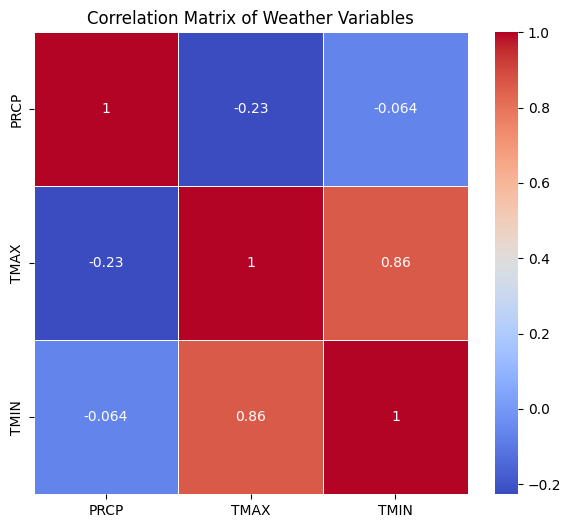

In [21]:
plt.figure(figsize=(7,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix of Weather Variables")

plt.show()

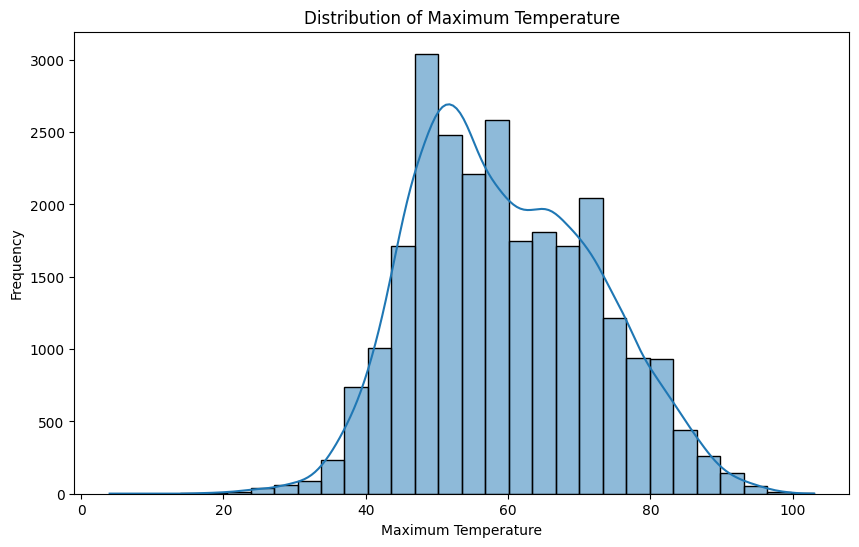

In [22]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["TMAX"],
    bins=30,
    kde=True
)

plt.title("Distribution of Maximum Temperature")
plt.xlabel("Maximum Temperature")
plt.ylabel("Frequency")

plt.show()

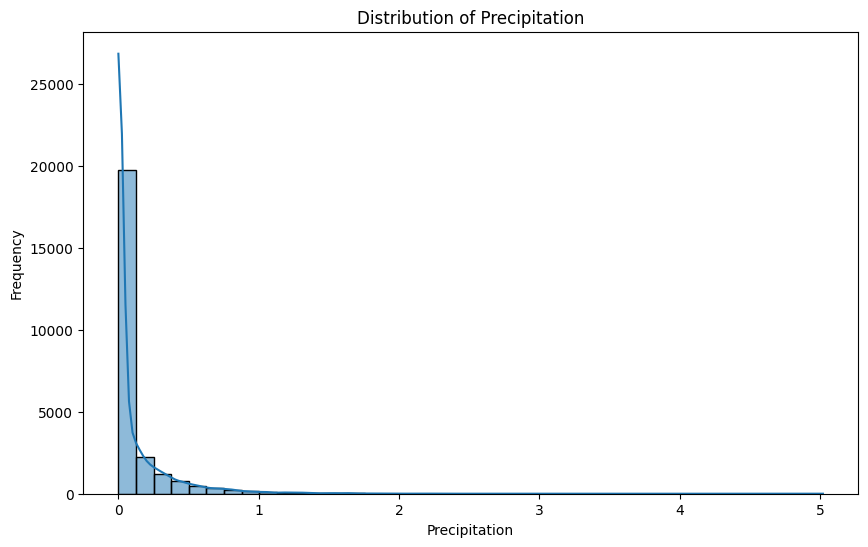

In [23]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["PRCP"],
    bins=40,
    kde=True
)

plt.title("Distribution of Precipitation")
plt.xlabel("Precipitation")
plt.ylabel("Frequency")

plt.show()

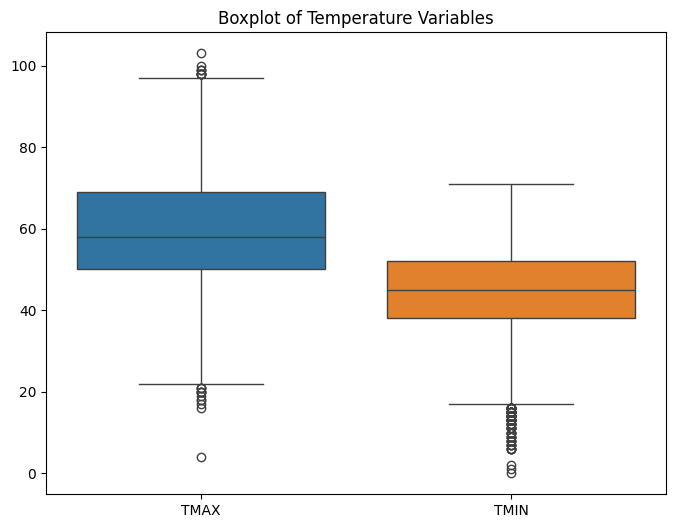

In [24]:
plt.figure(figsize=(8,6))

sns.boxplot(data=df[["TMAX", "TMIN"]])

plt.title("Boxplot of Temperature Variables")

plt.show()

In [25]:
Q1 = df["PRCP"].quantile(0.25)
Q3 = df["PRCP"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["PRCP"] < lower) | (df["PRCP"] > upper)]

print(outliers.shape)

(3558, 9)


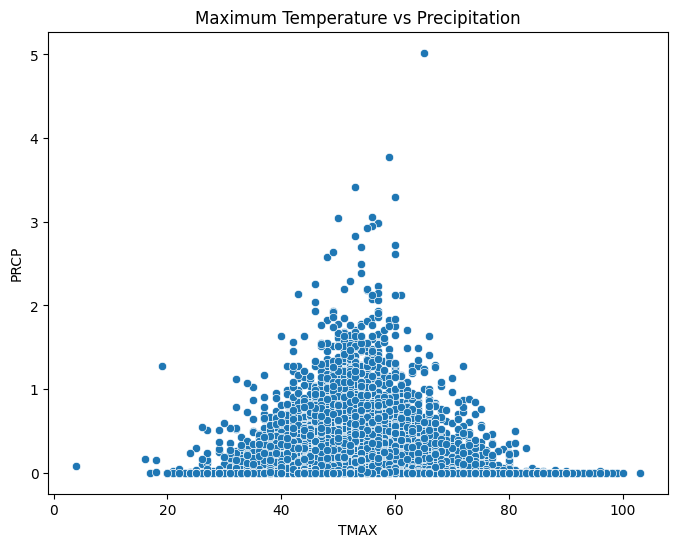

In [26]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x=df["TMAX"],
    y=df["PRCP"]
)

plt.title("Maximum Temperature vs Precipitation")

plt.xlabel("TMAX")
plt.ylabel("PRCP")

plt.show()

In [27]:
df["Rolling_TMAX"] = df["TMAX"].rolling(window=30).mean()

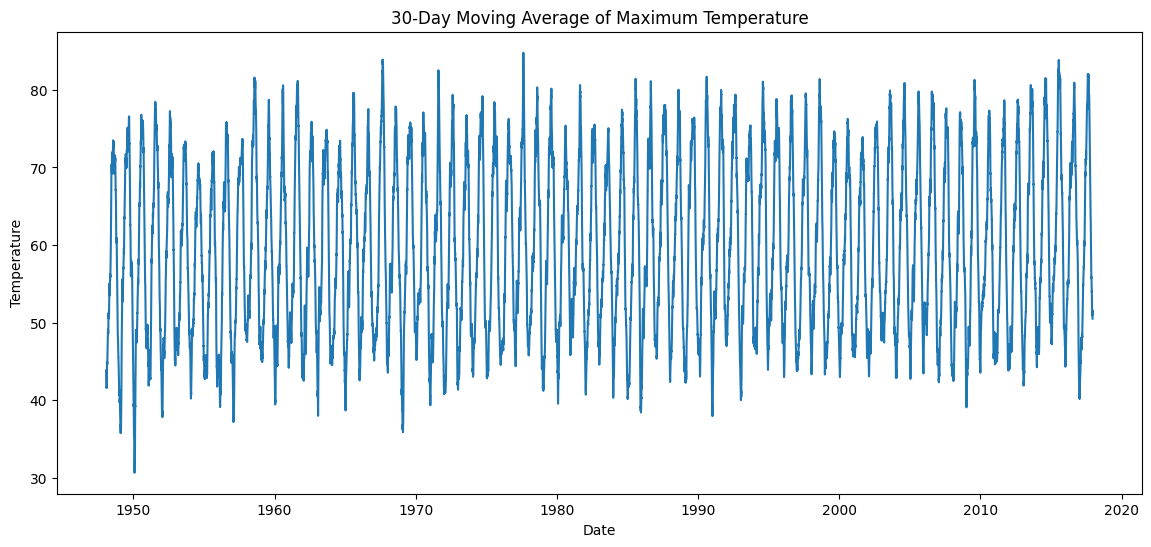

In [28]:
plt.figure(figsize=(14,6))

plt.plot(df["DATE"], df["Rolling_TMAX"])

plt.title("30-Day Moving Average of Maximum Temperature")

plt.xlabel("Date")
plt.ylabel("Temperature")

plt.show()

In [29]:
df["MONTH"] = df["DATE"].dt.month

In [30]:
monthly_temp = df.groupby("MONTH")["TMAX"].mean()

print(monthly_temp)

MONTH
1     45.131797
2     48.994944
3     52.321659
4     57.521905
5     64.309217
6     69.657606
7     75.497696
8     75.233180
9     69.632507
10    59.452535
11    50.587619
12    45.444909
Name: TMAX, dtype: float64


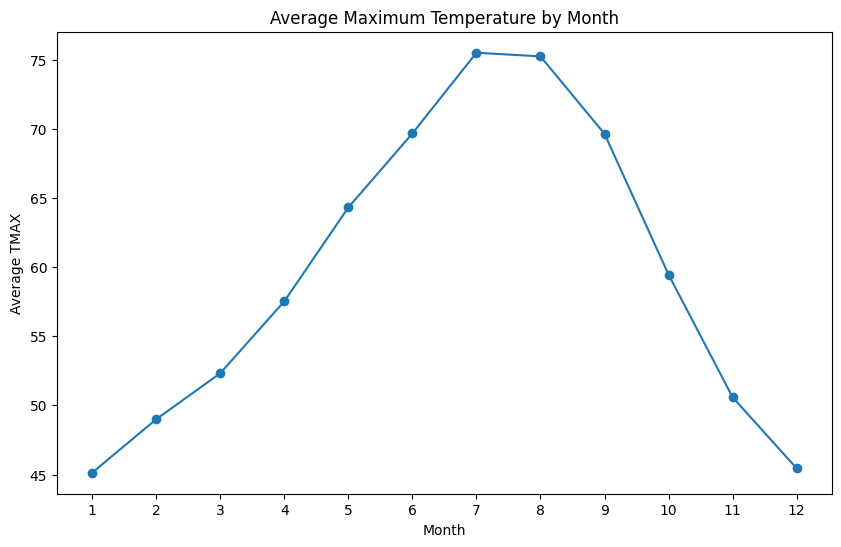

In [31]:
plt.figure(figsize=(10,6))

plt.plot(
    monthly_temp.index,
    monthly_temp.values,
    marker="o"
)

plt.title("Average Maximum Temperature by Month")

plt.xlabel("Month")
plt.ylabel("Average TMAX")

plt.xticks(range(1,13))

plt.show()

In [32]:
monthly_rain = df.groupby("MONTH")["PRCP"].mean()

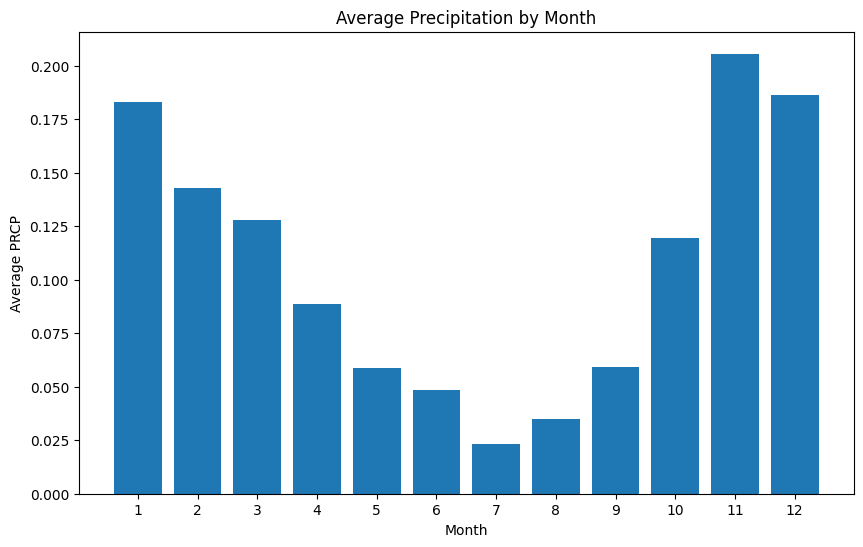

In [33]:
plt.figure(figsize=(10,6))

plt.bar(
    monthly_rain.index,
    monthly_rain.values
)

plt.title("Average Precipitation by Month")

plt.xlabel("Month")
plt.ylabel("Average PRCP")

plt.xticks(range(1,13))

plt.show()

In [34]:
import scipy.stats as stats

In [35]:
stat, p = stats.shapiro(df["TMAX"].sample(5000))

print("Test Statistic:", stat)
print("p-value:", p)

Test Statistic: 0.988726923302416
p-value: 1.4625262169158916e-19


In [36]:
rain_by_temp = df.groupby("TEMP_STATE")["RAIN"].mean()

print(rain_by_temp)

TEMP_STATE
Cold    0.579615
Hot      0.08037
Mild    0.513558
Name: RAIN, dtype: object


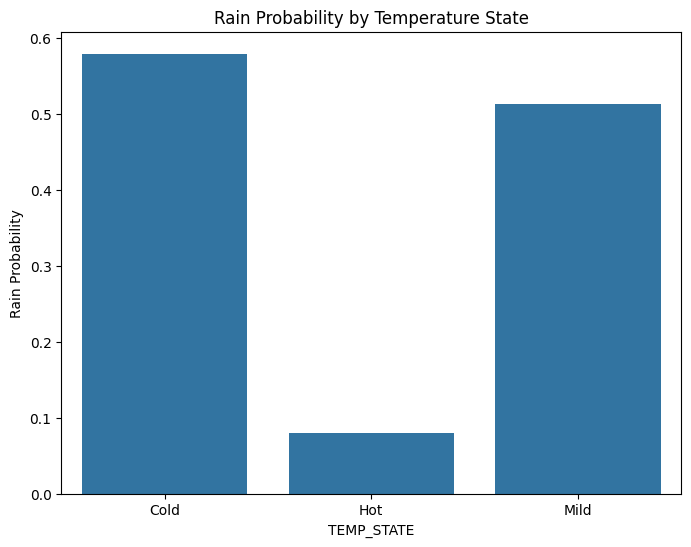

In [37]:
plt.figure(figsize=(8,6))

sns.barplot(
    x=rain_by_temp.index,
    y=rain_by_temp.values
)

plt.title("Rain Probability by Temperature State")

plt.ylabel("Rain Probability")

plt.show()

In [38]:
five_step = np.linalg.matrix_power(
    temp_transition_matrix.values,
    5
)

print(five_step)

[[0.39232924 0.11513253 0.49253823]
 [0.1157119  0.38708602 0.49720208]
 [0.22298618 0.22397057 0.55304325]]


In [39]:
persistence = np.diag(temp_transition_matrix)

print(persistence)

[0.77424667 0.76980321 0.79410012]


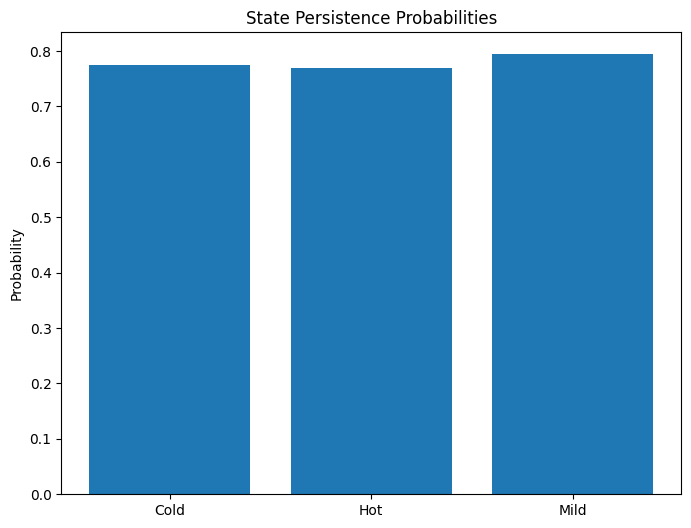

In [40]:
states = temp_transition_matrix.index

plt.figure(figsize=(8,6))

plt.bar(states, persistence)

plt.title("State Persistence Probabilities")

plt.ylabel("Probability")

plt.show()